<a href="https://colab.research.google.com/github/elikosarah/ICA-Stochastique-2026/blob/main/02_irmf_pica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 2. PICA sur IRM fonctionnelle (ADHD-200)

On applique une ICA probabiliste (PPCA puis ICA) à un sujet de la cohorte ADHD-200 : 176 volumes, environ 70 000 voxels. La question centrale est le **choix du nombre de composantes $q$**.

Les données (environ 100 Mo) sont téléchargées automatiquement par `nilearn` à la première exécution.

In [1]:
# Configuration : rend le module ica_stoch importable, en local comme sur Google Colab
import importlib.util, subprocess, sys
from pathlib import Path

REPO = "ICA-Stochastique-2026"
if importlib.util.find_spec("ica_stoch") is None:
    candidates = [Path.cwd(), *Path.cwd().parents, Path.cwd() / REPO, Path("/content") / REPO]
    root = next((p for p in candidates if (p / "src" / "ica_stoch").is_dir()), None)
    if root is None:  # ni dépôt local ni zip décompressé : on clone le dépôt GitHub
        subprocess.run(["git", "clone", "-q", f"https://github.com/elikosarah/{REPO}.git"], check=True)
        root = Path(REPO).resolve()
    sys.path.insert(0, str(root / "src"))

for pkg in ("mne", "nilearn"):  # absents par défaut sur Colab
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

In [2]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
from nilearn import plotting
from nilearn.image import index_img

from ica_stoch.fmri import load_adhd_subject, pca_eigenvalues, pica, select_q_bic

warnings.filterwarnings("ignore")
X, masker = load_adhd_subject()
print(f"T = {X.shape[0]} volumes, p = {X.shape[1]} voxels")

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


[fetch_adhd] Added README.md to /root/nilearn_data

[fetch_adhd] Dataset created in /root/nilearn_data/adhd

[fetch_adhd] Downloading data from https://www.nitrc.org/frs/download.php/7781/adhd40_metadata.tgz ...

[fetch_adhd]  ...done. (0 seconds, 0 min)

[fetch_adhd] Extracting data from /root/nilearn_data/adhd/fbef5baff0b388a8c913a08e1d84e059/adhd40_metadata.tgz...

... (2 outputs left out)

[fetch_adhd]  ...done. (1 seconds, 0 min)

[fetch_adhd] Extracting data from /root/nilearn_data/adhd/e7ff5670bd594dcd9453e57b55d69dc9/adhd40_0010042.tgz...

[fetch_adhd] .. done.

T = 176 volumes, p = 69681 voxels


## Choix de $q$

Trois estimations :
1. `PCA(n_components="mle")` de scikit-learn (Minka, 2000) appliquée après la PCA préliminaire ;
2. critère BIC de la PPCA avec l'estimateur du maximum de vraisemblance de $\sigma^2$ ;
3. le même critère avec l'estimation de $\sigma^2$ utilisée dans le rapport d'avril 2026 (moyenne des seules valeurs propres non nulles restantes), qui la surestime quand $p \gg T$.

À noter : le BIC compte $pq$ paramètres, avec $p \approx 70\,000$ voxels. Sa pénalité est donc très lourde quand $p \gg T$, et il peut retenir très peu de composantes. Les trois valeurs de $q$ sont à comparer avant de conclure.

scikit-learn 'mle' : q* = 173
BIC, σ² MV         : q* = 6
BIC, σ² rapport    : q* = 6


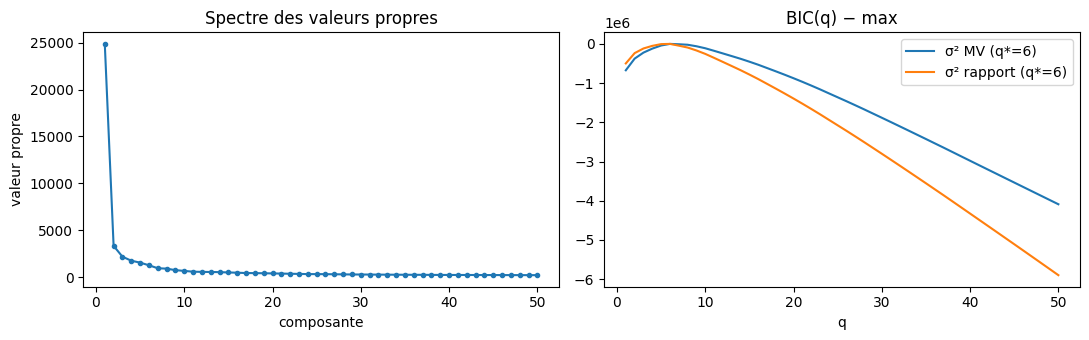

In [3]:
q_ml, bic_ml = select_q_bic(X, q_max=50, noise="ml")
q_legacy, bic_legacy = select_q_bic(X, q_max=50, noise="legacy")
res_mle = pica(X, q="mle")
print(f"scikit-learn 'mle' : q* = {res_mle.q}")
print(f"BIC, σ² MV         : q* = {q_ml}")
print(f"BIC, σ² rapport    : q* = {q_legacy}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
lam = pca_eigenvalues(X)
axes[0].plot(np.arange(1, 51), lam[:50], "o-", ms=3)
axes[0].set(title="Spectre des valeurs propres", xlabel="composante", ylabel="valeur propre")
for scores, q, lab in [(bic_ml, q_ml, "σ² MV"), (bic_legacy, q_legacy, "σ² rapport")]:
    axes[1].plot(np.arange(1, 51), scores - scores.max(), label=f"{lab} (q*={q})")
axes[1].set(title="BIC(q) − max", xlabel="q")
axes[1].legend()
fig.tight_layout()

## PICA avec le $q$ retenu

Les composantes sont classées par **kurtosis de leur carte spatiale** : une carte très non gaussienne est concentrée sur quelques régions, ce qu'on attend d'un réseau cérébral (ou d'un artefact localisé).

In [4]:
Q = q_ml  # à comparer avec q_legacy et res_mle.q ; une ICA n'a de sens que pour Q ≥ 2
results = {m: pica(X, q=Q, method=m, **({"n_epochs": 50} if m == "sgd" else {})) for m in ("fastica", "sgd")}
print(f"Kurtosis moyen des cartes — q = {res_mle.q} : {res_mle.map_kurtosis.mean():.2f}")
for m, r in results.items():
    print(f"Kurtosis moyen des cartes — q = {Q}, {m:7s} : {r.map_kurtosis.mean():.2f}")

Kurtosis moyen des cartes — q = 173 : 0.54
Kurtosis moyen des cartes — q = 6, fastica : 1.84
Kurtosis moyen des cartes — q = 6, sgd     : 2.02


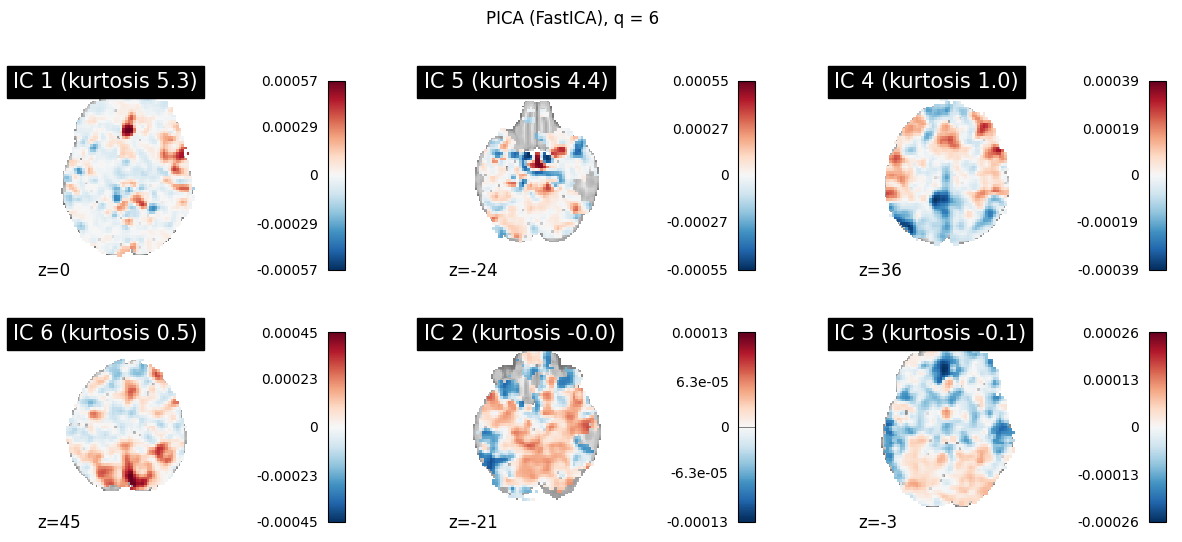

In [5]:
def show_top_maps(res, title, n=6):
    img = masker.inverse_transform(res.maps)
    fig, axes = plt.subplots(2, 3, figsize=(15, 6))
    for ax, idx in zip(axes.flat, res.ranking()[:n]):
        plotting.plot_stat_map(index_img(img, int(idx)), display_mode="z", cut_coords=1, axes=ax,
                               title=f"IC {idx + 1} (kurtosis {res.map_kurtosis[idx]:.1f})", colorbar=True)
    fig.suptitle(title)

show_top_maps(results["fastica"], f"PICA (FastICA), q = {Q}")

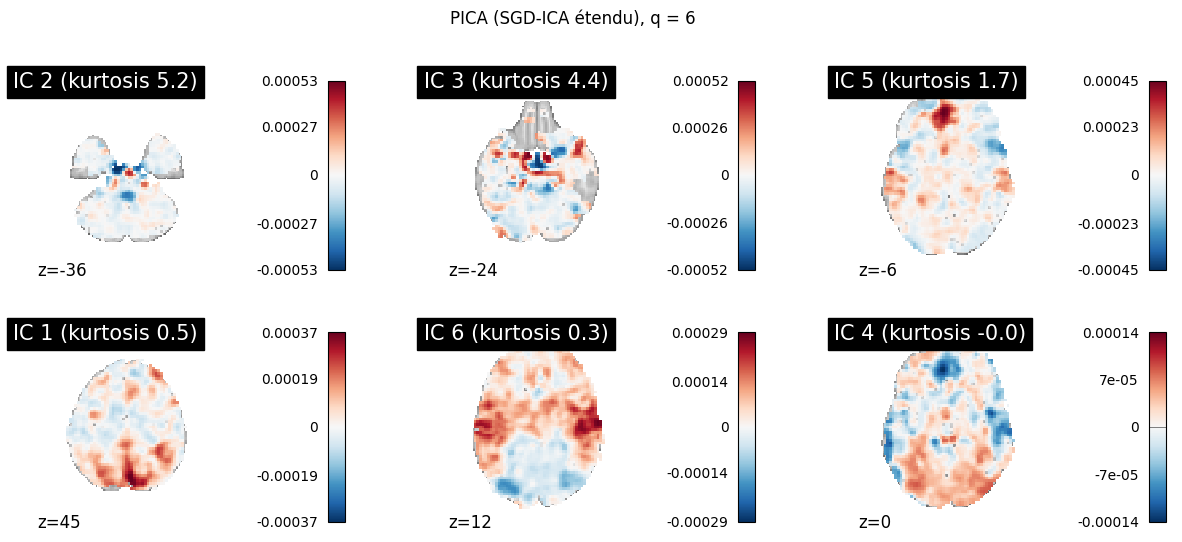

In [6]:
show_top_maps(results["sgd"], f"PICA (SGD-ICA étendu), q = {Q}")

## Limites

- Un seul sujet ; une ICA de groupe serait l'étape suivante.
- L'ICA est ici **temporelle** (les 176 volumes sont les observations). L'outil de référence en IRMf (MELODIC) fait une ICA **spatiale**, mieux adaptée quand $p \gg T$.
- Le kurtosis mesure la non-gaussianité, pas la plausibilité biologique : l'interprétation des cartes demande une comparaison avec des atlas de réseaux au repos.